In [166]:
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import random
import os

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from network.models import model_selection

In [167]:
test_path = r"C:\bunny\Deepfake-Detection\data\Dataset\Test"
model_path = "./output/best_weights/best.pkl"

batch_size = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [168]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet input size
    transforms.ToTensor()
])

full_test_dataset = ImageFolder(test_path, transform=transform)

# Separate indices by class
real_indices = [i for i, (_, label) in enumerate(full_test_dataset.samples) if label == 0]
fake_indices = [i for i, (_, label) in enumerate(full_test_dataset.samples) if label == 1]

random.shuffle(real_indices)
random.shuffle(fake_indices)

selected_indices = real_indices[:1000] + fake_indices[:1000]
random.shuffle(selected_indices)

test_dataset = Subset(full_test_dataset, selected_indices)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print("Classes:", full_test_dataset.classes)
print("Test samples used:", len(test_dataset))

Classes: ['Fake', 'Real']
Test samples used: 2000


In [169]:
model = model_selection(modelname='resnet18', num_out_classes=2, dropout=0.5)
model.load_state_dict(torch.load(model_path, map_location=device))
model = model.to(device)
model.eval()

print("Model loaded")

c:\Users\shara\AppData\Local\Programs\Python\Python314\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\shara\AppData\Local\Programs\Python\Python314\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model loaded


In [170]:
corrects = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        corrects += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = corrects / total
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.7945


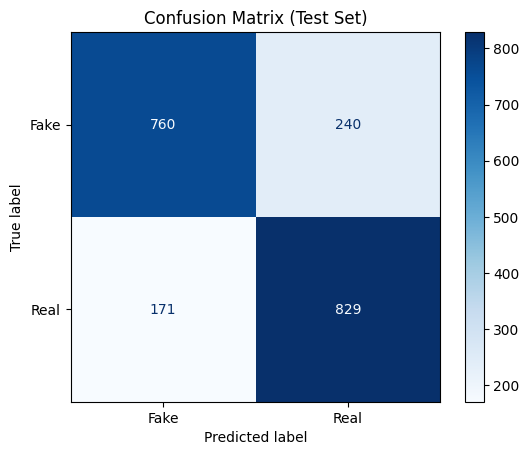

In [171]:
cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=full_test_dataset.classes
)

disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Test Set)")
plt.show()

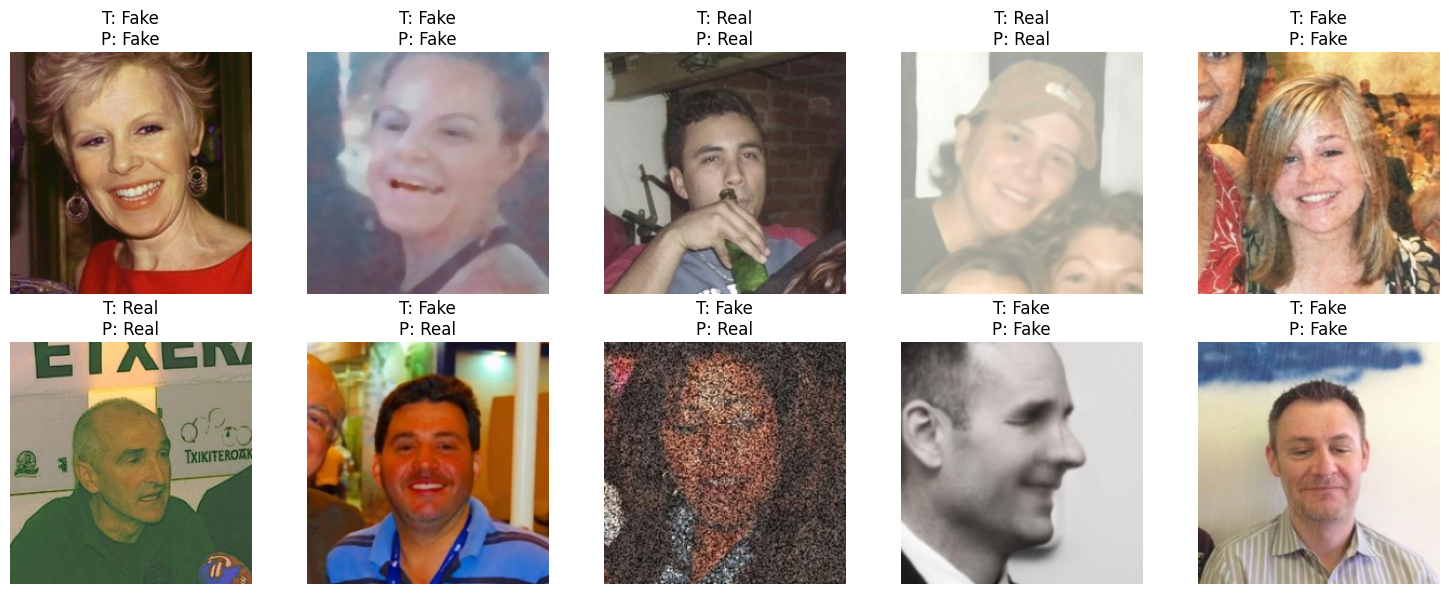

In [185]:
indices = random.sample(range(len(test_dataset)), 10)

plt.figure(figsize=(15,6))

for i, idx in enumerate(indices):
    img, label = test_dataset[idx]

    with torch.no_grad():
        pred = model(img.unsqueeze(0).to(device)).argmax(1).item()

    plt.subplot(2,5,i+1)
    plt.imshow(img.permute(1,2,0))
    plt.title(f"T: {full_test_dataset.classes[label]}\nP: {full_test_dataset.classes[pred]}")
    plt.axis("off")

plt.tight_layout()
plt.show()